# ch03_1. Fashion-MNIST MLP 학습과 평가

## 개요

- Fashion-MNIST(패션 엠니스트, 의류 이미지 데이터셋)의 10개 클래스를 확인합니다.
- `nn.Sequential`로 간단한 MLP(엠엘피, 다층 퍼셉트론)를 구성합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [2]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

### 1) 실행 장치 확인

이미 학습한 내용:

- `DataLoader`
- MLP 학습 반복문
- `CrossEntropyLoss()`
- Adam Optimizer
- 검증과 테스트
- 혼동행렬과 오분류 분석

 새로운 관찰:

```text
손글씨 숫자
→ 비교적 단순한 모양 구분

의류 이미지
→ 티셔츠·셔츠·풀오버·코트처럼 비슷한 모양 구분
```

따라서 전체 정확도뿐 아니라 **어떤 의류끼리 혼동하는지**가 중요합니다.

```text
Fashion-MNIST 다운로드
→ 의류 클래스와 이미지 확인
→ 훈련 55,000개·검증 5,000개·테스트 10,000개
→ MLP 기준 모델 학습
→ 최고 검증 가중치 복원
→ 테스트 최종 평가
→ 혼동행렬과 클래스별 정확도
→ 대표 오답 확인
→ 2픽셀 이동 민감도 확인
→ CNN 단계로 연결
```

GPU를 사용할 수 있으면 CUDA(쿠다, 엔비디아 GPU 연산 환경)를 사용하고, 그렇지 않으면 CPU를 사용합니다.

In [3]:
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

사용 장치: cuda


### 2) Fashion-MNIST의 10개 클래스

| 번호 | 영문 이름 | 한글 의미 |
|---:|---|---|
| 0 | T-shirt/top(티셔츠 탑) | 티셔츠·상의 |
| 1 | Trouser(트라우저) | 바지 |
| 2 | Pullover(풀오버) | 풀오버 |
| 3 | Dress(드레스) | 원피스 |
| 4 | Coat(코트) | 코트 |
| 5 | Sandal(샌들) | 샌들 |
| 6 | Shirt(셔츠) | 셔츠 |
| 7 | Sneaker(스니커) | 운동화 |
| 8 | Bag(백) | 가방 |
| 9 | Ankle boot(앵클 부트) | 앵클부츠 |

입력 형식:

```text
흑백 채널 1개
× 높이 28
× 너비 28
```

In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

class_names_ko = [
    "티셔츠",
    "바지",
    "풀오버",
    "원피스",
    "코트",
    "샌들",
    "셔츠",
    "운동화",
    "가방",
    "앵클부츠"
]

### 3) 데이터 분리

- 원래 훈련 데이터: 60,000개
- 실제 학습 데이터: 55,000개
- 검증 데이터: 5,000개
- 테스트 데이터: 10,000개

`ToTensor()`는 이미지를 Tensor로 변환하고 픽셀값을 0과 1 사이로 바꿉니다.

In [5]:
transform = transforms.ToTensor()

full_train_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    transform=transform,
    download=True
)

test_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR / "torchvision"),
    train=False,
    transform=transform,
    download=True
)

split_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [55_000, 5_000],
    generator=split_generator
)

print("학습 데이터:", len(train_dataset))

print("검증 데이터:", len(validation_dataset))

print("테스트 데이터:", len(test_dataset))

학습 데이터: 55000
검증 데이터: 5000
테스트 데이터: 10000


### 4) 결과 시각화

각 클래스에서 이미지 한 장씩 찾아 확인합니다.

숫자 이미지보다 상의 계열의 모양이 서로 비슷하다는 점을 관찰합니다.

/tmp/ipykernel_10447/3224134872.py:26: UserWarning: Glyph 54000 (\N{HANGUL SYLLABLE TI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3224134872.py:26: UserWarning: Glyph 49492 (\N{HANGUL SYLLABLE SYEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3224134872.py:26: UserWarning: Glyph 52768 (\N{HANGUL SYLLABLE CEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3224134872.py:26: UserWarning: Glyph 48148 (\N{HANGUL SYLLABLE BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3224134872.py:26: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3224134872.py:26: UserWarning: Glyph 54400 (\N{HANGUL SYLLABLE PUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3224134872.py:26: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tigh

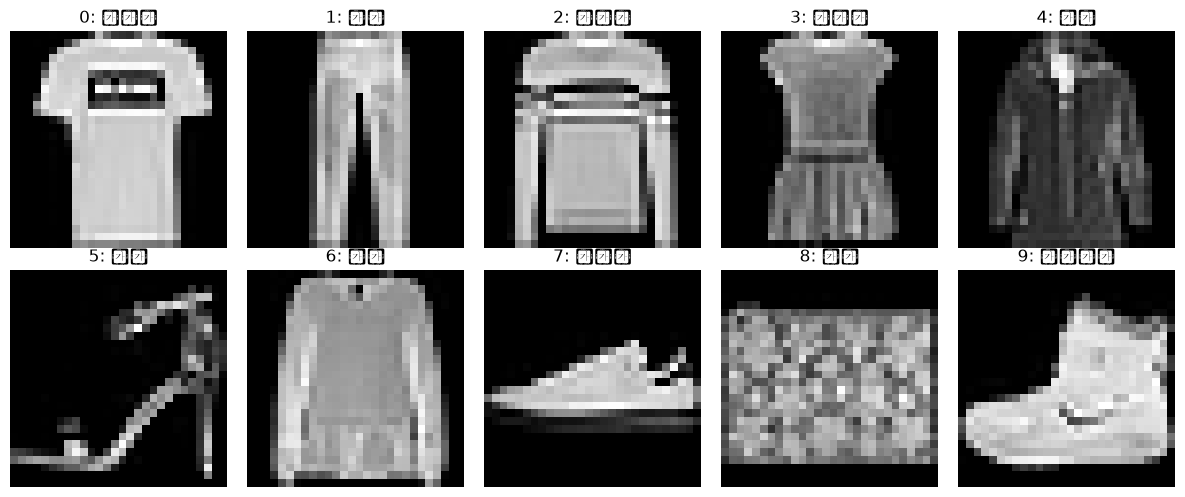

In [6]:
example_images = [None] * 10

for image, label in full_train_dataset:
    if example_images[label] is None:
        example_images[label] = image

    if all(image is not None for image in example_images):
        break

plt.figure(figsize=(12, 5))

for class_index, image in enumerate(example_images):
    plt.subplot(2, 5, class_index + 1)

    plt.imshow(
        image.squeeze(),
        cmap="gray"
    )

    plt.title(
        f"{class_index}: {class_names_ko[class_index]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

### 5) 배치 데이터 확인

- Batch Size(배치 사이즈): 128
- Epoch(에포크): 10
- 학습 데이터만 `shuffle=True`
- 검증·테스트 데이터는 `shuffle=False`

In [7]:
BATCH_SIZE = 128

NUMBER_OF_EPOCHS = 10

LEARNING_RATE = 0.001

loader_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

batch_images, batch_labels = next(
    iter(train_loader)
)

print("배치 이미지 shape:", batch_images.shape)

print("배치 정답 shape:", batch_labels.shape)

배치 이미지 shape: torch.Size([128, 1, 28, 28])
배치 정답 shape: torch.Size([128])


### 6) 모델 구성

```text
입력 [배치, 1, 28, 28]
→ Flatten
→ [배치, 784]
→ Linear(784, 256)
→ ReLU
→ Linear(256, 128)
→ ReLU
→ Linear(128, 10)
→ 의류별 로짓 10개
```

이번 모델은 CNN과 비교하기 위한 **기준 모델**입니다.

별도의 모델 클래스를 만들지 않고 `nn.Sequential`을 직접 사용합니다.

In [8]:
torch.manual_seed(RANDOM_SEED)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)

print(
    "학습 파라미터 수:",
    f"{number_of_parameters:,}개"
)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
)
학습 파라미터 수: 235,146개


### 7) Loss 함수와 Optimizer 설정

- 다중분류 손실함수: `nn.CrossEntropyLoss()`
- 가중치 갱신 방법: Adam(아담)
- 학습률: `0.001`

모델 마지막에는 Softmax를 넣지 않습니다.

In [9]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

### 8) 학습 함수 정의

같은 절차이므로 설명은 줄이고 함수로 정리합니다.

```text
학습
→ train()
→ 순전파
→ 손실
→ 역전파
→ 가중치 갱신

평가
→ eval()
→ no_grad()
→ 손실과 정확도 계산
```

In [10]:
def train_one_epoch(model, data_loader):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = loss_function(
            logits,
            labels
        )

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(dim=1)

        loss_sum += (
            loss.item() * images.size(0)
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 9) 평가 함수 정의

In [11]:
def evaluate_model(model, data_loader):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = loss_function(
                logits,
                labels
            )

            predictions = logits.argmax(dim=1)

            loss_sum += (
                loss.item() * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 10) 학습 기록과 최적 모델 준비

매 Epoch의 검증 정확도를 확인합니다.

검증 정확도가 가장 높아질 때의 가중치를 메모리에 보관하고, 학습이 끝나면 다시 적용합니다.

테스트 데이터는 모델 선택에 사용하지 않습니다.

In [12]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": []
}

best_validation_accuracy = -1.0

best_validation_loss = float("inf")

best_epoch = 0

best_model_state = copy.deepcopy(
    model.state_dict()
)

### 11) 모델 학습

In [13]:
for epoch in range(
    1,
    NUMBER_OF_EPOCHS + 1
):
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader
    )

    validation_loss, validation_accuracy = (
        evaluate_model(
            model,
            validation_loader
        )
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["validation_loss"].append(
        validation_loss
    )

    history["validation_accuracy"].append(
        validation_accuracy
    )

    is_better = (
        validation_accuracy
        > best_validation_accuracy
        or (
            validation_accuracy
            == best_validation_accuracy
            and validation_loss
            < best_validation_loss
        )
    )

    if is_better:
        best_validation_accuracy = (
            validation_accuracy
        )

        best_validation_loss = (
            validation_loss
        )

        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch {epoch:>2d}/{NUMBER_OF_EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Accuracy {train_accuracy:.4f} | "
        f"Validation Loss {validation_loss:.4f} | "
        f"Validation Accuracy {validation_accuracy:.4f}"
    )

Epoch  1/10 | Train Loss 0.5886 | Train Accuracy 0.7914 | Validation Loss 0.4506 | Validation Accuracy 0.8406
Epoch  2/10 | Train Loss 0.3990 | Train Accuracy 0.8559 | Validation Loss 0.4007 | Validation Accuracy 0.8538
Epoch  3/10 | Train Loss 0.3538 | Train Accuracy 0.8711 | Validation Loss 0.3789 | Validation Accuracy 0.8626
Epoch  4/10 | Train Loss 0.3245 | Train Accuracy 0.8817 | Validation Loss 0.3604 | Validation Accuracy 0.8716
Epoch  5/10 | Train Loss 0.3054 | Train Accuracy 0.8883 | Validation Loss 0.3712 | Validation Accuracy 0.8622
Epoch  6/10 | Train Loss 0.2891 | Train Accuracy 0.8930 | Validation Loss 0.3393 | Validation Accuracy 0.8758
Epoch  7/10 | Train Loss 0.2752 | Train Accuracy 0.8979 | Validation Loss 0.3276 | Validation Accuracy 0.8794
Epoch  8/10 | Train Loss 0.2621 | Train Accuracy 0.9024 | Validation Loss 0.3346 | Validation Accuracy 0.8770
Epoch  9/10 | Train Loss 0.2518 | Train Accuracy 0.9061 | Validation Loss 0.3287 | Validation Accuracy 0.8830
Epoch 10/1

### 12) 학습 기록과 최적 모델 준비

In [14]:
model.load_state_dict(
    best_model_state
)

print()

print("최고 검증 Epoch:", best_epoch)

print(
    "최고 검증 정확도:",
    f"{best_validation_accuracy:.4f}"
)


최고 검증 Epoch: 10
최고 검증 정확도: 0.8884


### 13) 학습 Loss 시각화

훈련 손실은 감소하지만 검증 손실이 다시 증가하면 과적합 가능성이 있습니다.

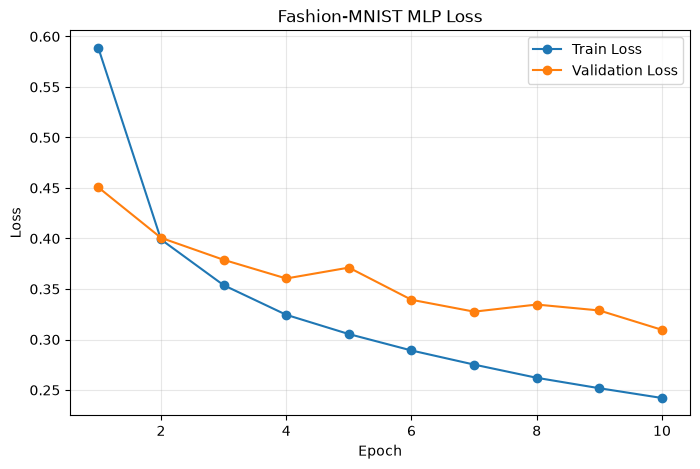

In [15]:
epoch_numbers = range(
    1,
    NUMBER_OF_EPOCHS + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epoch_numbers,
    history["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Fashion-MNIST MLP Loss")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 14) 학습 정확도 시각화

훈련 정확도와 검증 정확도의 차이가 지나치게 커지는지 확인합니다.

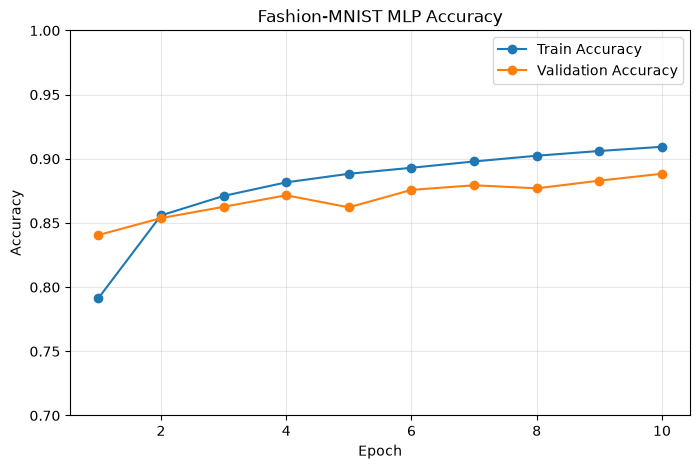

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epoch_numbers,
    history["validation_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Fashion-MNIST MLP Accuracy")

plt.ylim(0.7, 1.0)

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 15) 테스트 성능 확인

최고 검증 가중치를 복원한 모델 하나만 테스트 데이터로 평가합니다.

In [17]:
test_loss, test_accuracy = evaluate_model(
    model,
    test_loader
)

print(f"테스트 손실: {test_loss:.4f}")

print(f"테스트 정확도: {test_accuracy:.4f}")

print(
    f"맞힌 이미지 수: "
    f"{int(test_accuracy * len(test_dataset)):,}"
    f" / {len(test_dataset):,}"
)

테스트 손실: 0.3228
테스트 정확도: 0.8894
맞힌 이미지 수: 8,894 / 10,000


### 16) 데이터 구조 확인

이후 분석에서 모델을 반복 실행하지 않도록 다음 결과를 한 번에 모읍니다.

- 이미지
- 실제 클래스
- 예측 클래스
- 예측 확률

In [18]:
image_batches = []

label_batches = []

logit_batches = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(
            images.to(device)
        ).cpu()

        image_batches.append(
            images
        )

        label_batches.append(
            labels
        )

        logit_batches.append(
            logits
        )

all_images = torch.cat(
    image_batches
)

all_labels = torch.cat(
    label_batches
)

all_logits = torch.cat(
    logit_batches
)

all_probabilities = torch.softmax(
    all_logits,
    dim=1
)

all_confidences, all_predictions = (
    all_probabilities.max(dim=1)
)

print("전체 이미지 shape:", all_images.shape)

print("전체 예측 shape:", all_predictions.shape)

전체 이미지 shape: torch.Size([10000, 1, 28, 28])
전체 예측 shape: torch.Size([10000])


### 17) Confusion Matrix 준비

```text
행: 실제 의류
열: 예측 의류
대각선: 올바른 예측
대각선 밖: 잘못된 예측
```

대각선 밖의 큰 값은 모델이 자주 혼동하는 의류 관계입니다.

In [19]:
confusion_matrix = torch.zeros(
    10,
    10,
    dtype=torch.int64
)

### 18) Confusion Matrix 계산

In [20]:
for actual, predicted in zip(
    all_labels,
    all_predictions
):
    confusion_matrix[
        actual,
        predicted
    ] += 1

### 19) Confusion Matrix 시각화

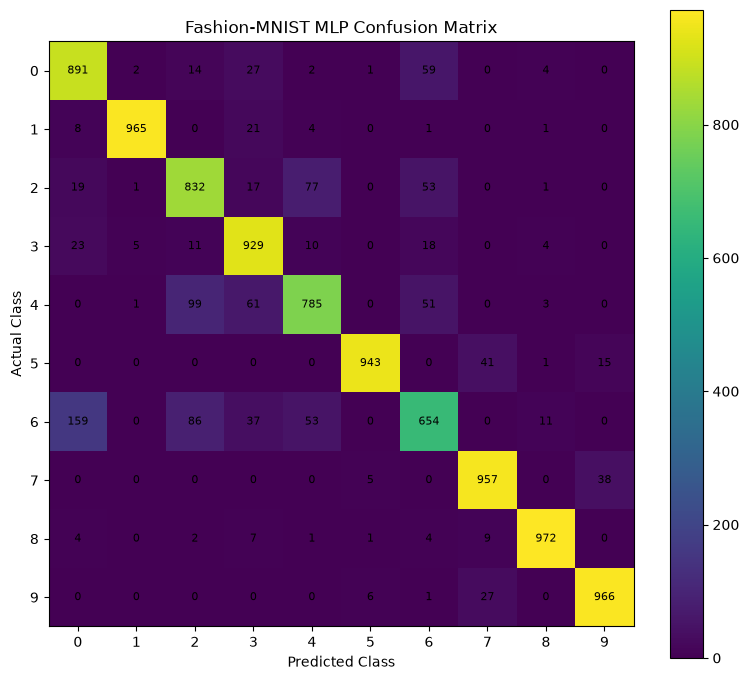

In [21]:
plt.figure(figsize=(8, 7))

plt.imshow(
    confusion_matrix.numpy()
)

plt.xticks(
    range(10),
    range(10)
)

plt.yticks(
    range(10),
    range(10)
)

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.title("Fashion-MNIST MLP Confusion Matrix")

for row in range(10):
    for column in range(10):
        plt.text(
            column,
            row,
            int(confusion_matrix[row, column]),
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar()

plt.tight_layout()

plt.show()

### 20) 모델 구성

클래스별 정확도:

```text
해당 의류를 맞힌 개수
÷ 해당 의류의 전체 개수
```

전체 정확도에 가려진 약한 의류를 찾습니다.

In [22]:
class_correct = confusion_matrix.diag()

class_total = confusion_matrix.sum(
    dim=1
)

class_accuracy = (
    class_correct.float()
    / class_total
)

for class_index in range(10):
    print(
        f"{class_index}: "
        f"{class_names_ko[class_index]:<6} | "
        f"{class_accuracy[class_index].item():.4f}"
    )

lowest_class = torch.argmin(
    class_accuracy
).item()

print()

print(
    "가장 낮은 정확도의 의류:",
    class_names_ko[lowest_class]
)

0: 티셔츠    | 0.8910
1: 바지     | 0.9650
2: 풀오버    | 0.8320
3: 원피스    | 0.9290
4: 코트     | 0.7850
5: 샌들     | 0.9430
6: 셔츠     | 0.6540
7: 운동화    | 0.9570
8: 가방     | 0.9720
9: 앵클부츠   | 0.9660

가장 낮은 정확도의 의류: 셔츠


### 21) 클래스별 정확도 확인

/tmp/ipykernel_10447/2291829532.py:27: UserWarning: Glyph 54000 (\N{HANGUL SYLLABLE TI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/2291829532.py:27: UserWarning: Glyph 49492 (\N{HANGUL SYLLABLE SYEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/2291829532.py:27: UserWarning: Glyph 52768 (\N{HANGUL SYLLABLE CEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/2291829532.py:27: UserWarning: Glyph 48148 (\N{HANGUL SYLLABLE BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/2291829532.py:27: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/2291829532.py:27: UserWarning: Glyph 54400 (\N{HANGUL SYLLABLE PUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/2291829532.py:27: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tigh

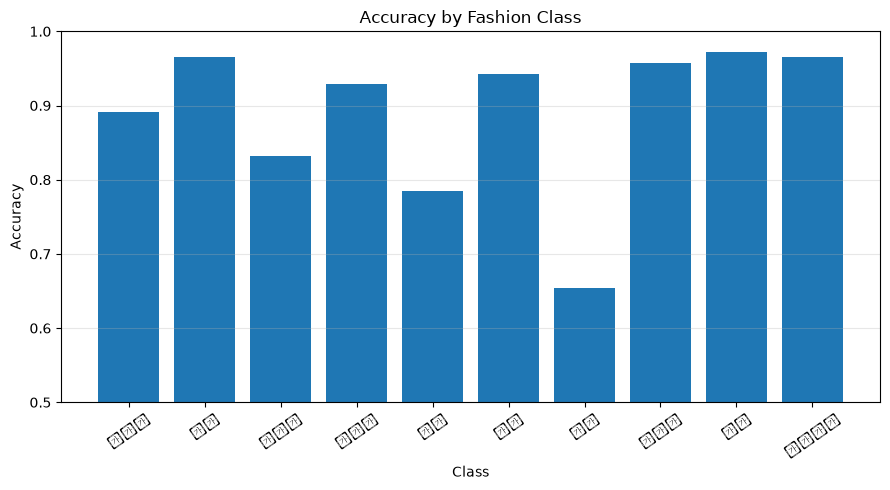

In [23]:
plt.figure(figsize=(9, 5))

plt.bar(
    range(10),
    class_accuracy.numpy()
)

plt.xticks(
    range(10),
    class_names_ko,
    rotation=35
)

plt.ylim(0.5, 1.0)

plt.xlabel("Class")

plt.ylabel("Accuracy")

plt.title("Accuracy by Fashion Class")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

### 22) 주요 오분류 확인

혼동행렬의 대각선을 제외하고 가장 큰 값을 찾습니다.

방향을 구분해야 합니다.

```text
실제 셔츠 → 예측 티셔츠
```

위 관계와 다음 관계는 서로 다른 오류입니다.

```text
실제 티셔츠 → 예측 셔츠
```

In [24]:
wrong_confusion = confusion_matrix.clone()

wrong_confusion.fill_diagonal_(0)

flat_index = wrong_confusion.argmax().item()

confused_actual = flat_index // 10

confused_predicted = flat_index % 10

confused_count = wrong_confusion[
    confused_actual,
    confused_predicted
].item()

print(
    f"실제 {class_names_ko[confused_actual]} "
    f"→ 예측 {class_names_ko[confused_predicted]}: "
    f"{confused_count}개"
)

실제 셔츠 → 예측 티셔츠: 159개


### 23) 오분류 데이터 확인

대표 오답 12개를 확인합니다.

- `A`: 실제 클래스
- `P`: 예측 클래스
- `C`: 모델의 예측 확률

/tmp/ipykernel_10447/3599586683.py:56: UserWarning: Glyph 53076 (\N{HANGUL SYLLABLE KO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3599586683.py:56: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3599586683.py:56: UserWarning: Glyph 54400 (\N{HANGUL SYLLABLE PUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3599586683.py:56: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3599586683.py:56: UserWarning: Glyph 48260 (\N{HANGUL SYLLABLE BEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3599586683.py:56: UserWarning: Glyph 50549 (\N{HANGUL SYLLABLE AENG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10447/3599586683.py:56: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.t

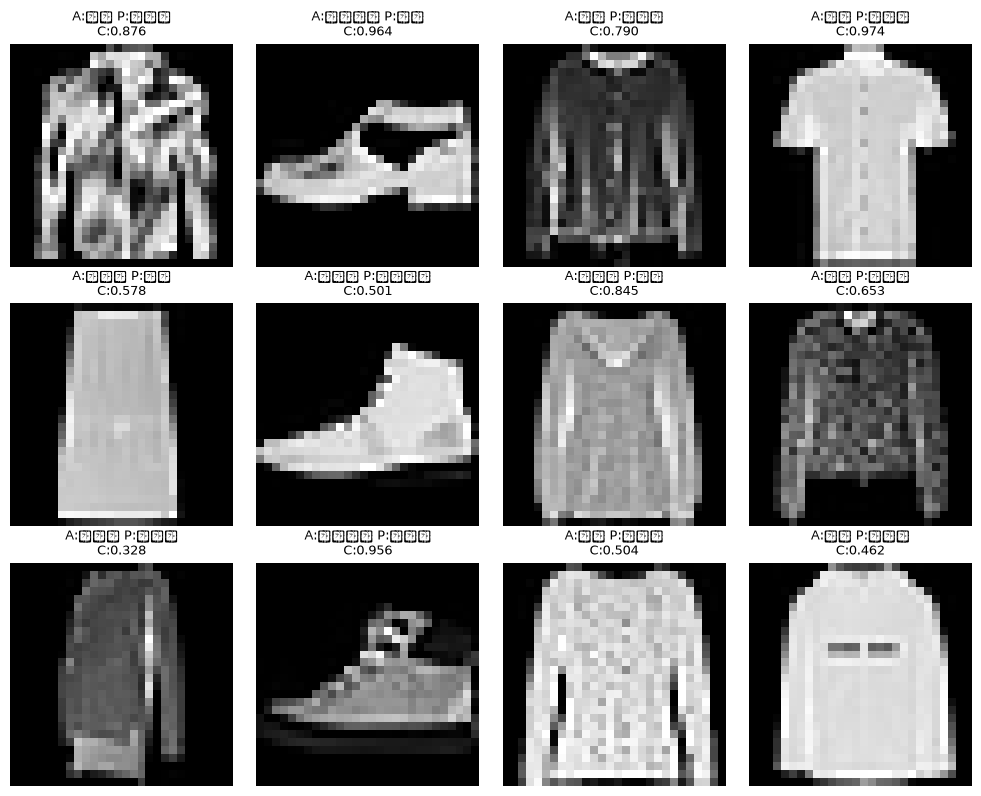

In [25]:
wrong_mask = (
    all_predictions != all_labels
)

wrong_images = all_images[
    wrong_mask
]

wrong_labels = all_labels[
    wrong_mask
]

wrong_predictions = all_predictions[
    wrong_mask
]

wrong_confidences = all_confidences[
    wrong_mask
]

number_of_examples = min(
    12,
    len(wrong_images)
)

plt.figure(figsize=(10, 8))

for index in range(number_of_examples):
    plt.subplot(
        3,
        4,
        index + 1
    )

    plt.imshow(
        wrong_images[index].squeeze(),
        cmap="gray"
    )

    actual_name = class_names_ko[
        wrong_labels[index].item()
    ]

    predicted_name = class_names_ko[
        wrong_predictions[index].item()
    ]

    plt.title(
        f"A:{actual_name} P:{predicted_name}\n"
        f"C:{wrong_confidences[index].item():.3f}",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

### 24) 이미지 위치를 2픽셀 이동하기

사람에게는 같은 의류이지만, 이미지의 위치가 달라지면 MLP에는 다른 픽셀 위치가 활성화됩니다.

```text
원본 이미지
→ 오른쪽으로 2픽셀 이동
→ 새로 생긴 왼쪽 영역은 0으로 채움
```

In [26]:
def shift_right(images, pixels=2):
    shifted = torch.zeros_like(
        images
    )

    shifted[
        :,
        :,
        :,
        pixels:
    ] = images[
        :,
        :,
        :,
        :-pixels
    ]

    return shifted

### 25) 결과 시각화

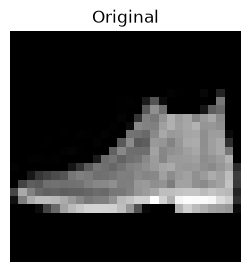

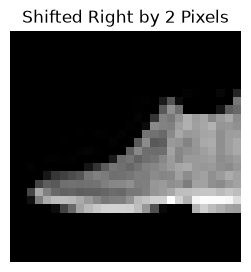

In [27]:
original_image = all_images[:1]

shifted_image = shift_right(
    original_image,
    pixels=2
)

plt.figure(figsize=(3, 3))

plt.imshow(
    original_image[0].squeeze(),
    cmap="gray"
)

plt.title("Original")

plt.axis("off")

plt.show()

plt.figure(figsize=(3, 3))

plt.imshow(
    shifted_image[0].squeeze(),
    cmap="gray"
)

plt.title("Shifted Right by 2 Pixels")

plt.axis("off")

plt.show()

### 26) 테스트 성능 확인

- 원본 정확도
- 2픽셀 이동 정확도
- 정확도 감소
- 예측 클래스 변경 비율

작은 위치 변화에도 결과가 크게 달라진다면 MLP가 위치 변화에 민감하다는 의미입니다.

In [28]:
model.eval()

shifted_correct = 0

prediction_changed = 0

total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        shifted_images = shift_right(
            images,
            pixels=2
        )

        original_predictions = model(
            images
        ).argmax(dim=1)

        shifted_predictions = model(
            shifted_images
        ).argmax(dim=1)

        shifted_correct += (
            shifted_predictions == labels
        ).sum().item()

        prediction_changed += (
            shifted_predictions
            != original_predictions
        ).sum().item()

        total += labels.size(0)

shifted_accuracy = (
    shifted_correct / total
)

prediction_change_rate = (
    prediction_changed / total
)

accuracy_drop = (
    test_accuracy - shifted_accuracy
)

print(f"원본 정확도: {test_accuracy:.4f}")

원본 정확도: 0.8894


### 27) 이동 이미지 성능 확인

In [29]:
print(
    f"2픽셀 이동 정확도: "
    f"{shifted_accuracy:.4f}"
)

print(
    f"정확도 감소: "
    f"{accuracy_drop:.4f}"
)

print(
    f"예측 클래스 변경 비율: "
    f"{prediction_change_rate:.4f}"
)

2픽셀 이동 정확도: 0.5427
정확도 감소: 0.3467
예측 클래스 변경 비율: 0.4327


### 28) 모델 저장

Checkpoint에는 다음 내용을 저장합니다.

- 모델 가중치
- 은닉층 크기
- 클래스 이름
- 최고 검증 Epoch와 정확도
- 테스트 정확도
- 이미지 크기

In [30]:
checkpoint_path = MODEL_DIR / "ch03_1_best_fashion_mnist_mlp.pt"

checkpoint = {
    "model_state_dict": model.state_dict(),
    "hidden_sizes": [256, 128],
    "number_of_classes": 10,
    "class_names": class_names,
    "class_names_ko": class_names_ko,
    "image_size": [1, 28, 28],
    "best_epoch": best_epoch,
    "validation_loss": best_validation_loss,
    "validation_accuracy": best_validation_accuracy,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy
}

torch.save(
    checkpoint,
    checkpoint_path
)

loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("저장 파일:", checkpoint_path)

print(
    "저장된 검증 정확도:",
    f"{loaded_checkpoint['validation_accuracy']:.4f}"
)

print(
    "저장된 테스트 정확도:",
    f"{loaded_checkpoint['test_accuracy']:.4f}"
)

저장 파일: models/ch04_5_best_fashion_mnist_mlp.pt
저장된 검증 정확도: 0.8884
저장된 테스트 정확도: 0.8894
